In [2]:
!wget https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Parainfluenza/geography_types/Nation/geographies/England/metrics/parainfluenza_testing_positivityByWeek


--2026-10-22 21:17:46--  https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Parainfluenza/geography_types/Nation/geographies/England/metrics/parainfluenza_testing_positivityByWeek
Resolving api.ukhsa-dashboard.data.gov.uk (api.ukhsa-dashboard.data.gov.uk)... 108.138.217.88, 108.138.217.92, 108.138.217.42, ...
Connecting to api.ukhsa-dashboard.data.gov.uk (api.ukhsa-dashboard.data.gov.uk)|108.138.217.88|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2194 (2.1K) [application/json]
Saving to: ‘parainfluenza_testing_positivityByWeek.3’

parainfluenza_testi 100%[===================>]   2.14K  --.-KB/s    in 0s      

2026-10-22 21:17:47 (771 MB/s) - ‘parainfluenza_testing_positivityByWeek.3’ saved [2194/2194]



In [3]:
!cat parainfluenza_testing_positivityByWeek

{"count":479,"next":"https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Parainfluenza/geography_types/UKHSA%20Region/geographies/Yorkshire%20and%20Humber/metrics/parainfluenza_testing_positivityByWeek?page=2","previous":null,"results":[{"theme":"infectious_disease","sub_theme":"respiratory","topic":"Parainfluenza","geography_type":"UKHSA Region","geography":"Yorkshire and Humber","geography_code":"E45000010","metric":"parainfluenza_testing_positivityByWeek","metric_group":"testing","stratum":"default","sex":"all","age":"all","year":2017,"month":7,"epiweek":27,"date":"2017-07-03","metric_value":1.98,"in_reporting_delay_period":false},{"theme":"infectious_disease","sub_theme":"respiratory","topic":"Parainfluenza","geography_type":"UKHSA Region","geography":"Yorkshire and Humber","geography_code":"E45000010","metric":"parainfluenza_testing_positivityByWeek","metric_group":"testing","stratum":"default","sex":"all","age":"all","year":2017,"month"

In [4]:
import requests

requests.get("https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Parainfluenza/geography_types/Nation/geographies/England/metrics/parainfluenza_testing_positivityByWeek", 
             params={'year': 2026, 'page_size': 3, 'page': 2}).json()

{'count': 273,
 'next': 'https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Parainfluenza/geography_types/Nation/geographies/England/metrics/parainfluenza_testing_positivityByWeek?page=3&page_size=3&year=2026',
 'previous': 'https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/respiratory/topics/Parainfluenza/geography_types/Nation/geographies/England/metrics/parainfluenza_testing_positivityByWeek?page_size=3&year=2026',
 'results': [{'theme': 'infectious_disease',
   'sub_theme': 'respiratory',
   'topic': 'Parainfluenza',
   'geography_type': 'Nation',
   'geography': 'England',
   'geography_code': 'E92000001',
   'metric': 'parainfluenza_testing_positivityByWeek',
   'metric_group': 'testing',
   'stratum': 'default',
   'sex': 'all',
   'age': 'all',
   'year': 2026,
   'month': 1,
   'epiweek': 2,
   'date': '2026-01-05',
   'metric_value': 3.04,
   'in_reporting_delay_period': False},
  {'theme': 'infectious_di

In [5]:
import requests
import time

class APIwrapper:
    # class variables shared among all instances
    _access_point="https://api.ukhsa-dashboard.data.gov.uk"
    _last_access=0.0 # time of last api access
    
    def __init__(self, theme, sub_theme, topic, geography_type, geography, metric):
        """ Init the APIwrapper object, constructing the endpoint from the structure
        parameters """
        # build the path with all the required structure parameters. You do not need to edit this line,
        # parameters will be replaced by the actual values when you instantiate an object of the class!
        url_path=(f"/themes/{theme}/sub_themes/{sub_theme}/topics/{topic}/geography_types/" +
                  f"{geography_type}/geographies/{geography}/metrics/{metric}")
        # our starting API endpoint
        self._start_url=APIwrapper._access_point+url_path
        self._filters=None
        self._page_size=-1
        # will contain the number of items
        self.count=None

    def get_page(self, filters={}, page_size=5):
        """ Access the API and download the next page of data. Sets the count
        attribute to the total number of items available for this query. Changing
        filters or page_size will cause get_page to restart from page 1. Rate
        limited to three request per second. The page_size parameter sets the number
        of data points in one response page (maximum 365); use the default value 
        for debugging your structure and filters. """
        # Check page size is within range
        if page_size>365:
            raise ValueError("Max supported page size is 365")
        # restart from first page if page or filters have changed
        if filters!=self._filters or page_size!=self._page_size:
            self._filters=filters
            self._page_size=page_size
            self._next_url=self._start_url
        # signal the end of data condition
        if self._next_url==None: 
            return [] # we already fetched the last page
        # simple rate limiting to avoid bans
        curr_time=time.time() # Unix time: number of seconds since the Epoch
        deltat=curr_time-APIwrapper._last_access
        if deltat<0.33: # max 3 requests/second
            time.sleep(0.33-deltat)
        APIwrapper._last_access=curr_time
        # build parameter dictionary by removing all the None
        # values from filters and adding page_size
        parameters={x: y for x, y in filters.items() if y!=None}
        parameters['page_size']=page_size
        # the page parameter is already included in _next_url.
        # This is the API access. Response is a dictionary with various keys.
        # the .json() method decodes the response into Python object (dictionaries,
        # lists; 'null' values are translated as None).
        response = requests.get(self._next_url, params=parameters).json()
        # update url so we'll fetch the next page
        self._next_url=response['next']
        self.count=response['count']
        # data are in the nested 'results' list
        return response['results'] 

    def get_all_pages(self, filters={}, page_size=365):
        """ Access the API and download all available data pages of data. Sets the count
        attribute to the total number of items available for this query. API access rate
        limited to three request per second. The page_size parameter sets the number
        of data points in one response page (maximum 365), and controls the trade-off
        between time to load a page and number of pages; the default should work well 
        in most cases. The number of items returned should in any case be equal to 
        the count attribute. """
        data=[] # build up all data here
        while True:
            # use get_page to do the job, including the pacing
            next_page=self.get_page(filters, page_size)
            if next_page==[]:
                break # we are done
            data.extend(next_page)
        return data

In [6]:
structure={"theme": "infectious_disease", 
           "sub_theme": "respiratory",
           "topic": "Parainfluenza",
           "geography_type": "Nation", 
           "geography": "England"}

In [7]:
structure["metric"]="parainfluenza_testing_positivityByWeek"

In [8]:
api=APIwrapper(**structure)
data=api.get_page() # default size is 5
print(api.count)
print(data)

3381
[{'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Parainfluenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'parainfluenza_testing_positivityByWeek', 'metric_group': 'testing', 'stratum': 'default', 'sex': 'all', 'age': '00-04', 'year': 2017, 'month': 7, 'epiweek': 27, 'date': '2017-07-03', 'metric_value': 4.86, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Parainfluenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'parainfluenza_testing_positivityByWeek', 'metric_group': 'testing', 'stratum': 'default', 'sex': 'all', 'age': '80+', 'year': 2017, 'month': 7, 'epiweek': 27, 'date': '2017-07-03', 'metric_value': 3.17, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Parainfluenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_cod

In [9]:
filters={"stratum" : None, # Smallest subgroup a metric can be broken down into e.g. ethnicity, testing pillar
         "age": None, # Smallest subgroup a metric can be broken down into e.g. 15_44 for the age group of 15-44 years
         "sex": None, #  Patient gender e.g. 'm' for Male, 'f' for Female or 'all' for all genders
         "year": 2026, #  Epi year of the metrics value (important for annual metrics) e.g. 2020
         "month": None, # Epi month of the metric value (important for monthly metrics) e.g. 12
         "epiweek" :None, # Epi week of the metric value (important for weekly metrics) e.g. 30
         "date" : None, # The date which this metric value was recorded in the format YYYY-MM-DD e.g. 2020-07-20
         "in_reporting_delay_period": None # Boolean indicating whether the data point is considered to be subject to retrospective updates
        }

In [10]:
data_2026=api.get_page(filters, page_size=3)
print(api.count)
print(data_2026)

273
[{'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Parainfluenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'parainfluenza_testing_positivityByWeek', 'metric_group': 'testing', 'stratum': 'default', 'sex': 'all', 'age': '65-79', 'year': 2026, 'month': 1, 'epiweek': 2, 'date': '2026-01-05', 'metric_value': 2.01, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Parainfluenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code': 'E92000001', 'metric': 'parainfluenza_testing_positivityByWeek', 'metric_group': 'testing', 'stratum': 'default', 'sex': 'all', 'age': '00-04', 'year': 2026, 'month': 1, 'epiweek': 2, 'date': '2026-01-05', 'metric_value': 6.39, 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Parainfluenza', 'geography_type': 'Nation', 'geography': 'England', 'geography_code

In [11]:
structure["metric"]="parainfluenza_testing_positivityByWeek"
api=APIwrapper(**structure)
cases=api.get_all_pages()
print(f"Data points expected: {api.count}")
print(f"Data points retrieved: {len(cases)}")

Data points expected: 3381
Data points retrieved: 3381


In [12]:
import json

In [14]:
with open("positivity.json", "wt") as OUTF:
    json.dump(cases, OUTF)

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import json

In [17]:
# an iPython  "magic" that enables the embedding of matplotlib output
%matplotlib inline
# make figures larger
plt.rcParams['figure.dpi'] = 100

In [22]:
with open("positivity.json", "rt") as INFILE:
    cases=json.load(INFILE)

In [23]:
cases[:5]

[{'theme': 'infectious_disease',
  'sub_theme': 'respiratory',
  'topic': 'Parainfluenza',
  'geography_type': 'Nation',
  'geography': 'England',
  'geography_code': 'E92000001',
  'metric': 'parainfluenza_testing_positivityByWeek',
  'metric_group': 'testing',
  'stratum': 'default',
  'sex': 'all',
  'age': '00-04',
  'year': 2017,
  'month': 7,
  'epiweek': 27,
  'date': '2017-07-03',
  'metric_value': 4.86,
  'in_reporting_delay_period': False},
 {'theme': 'infectious_disease',
  'sub_theme': 'respiratory',
  'topic': 'Parainfluenza',
  'geography_type': 'Nation',
  'geography': 'England',
  'geography_code': 'E92000001',
  'metric': 'parainfluenza_testing_positivityByWeek',
  'metric_group': 'testing',
  'stratum': 'default',
  'sex': 'all',
  'age': '80+',
  'year': 2017,
  'month': 7,
  'epiweek': 27,
  'date': '2017-07-03',
  'metric_value': 3.17,
  'in_reporting_delay_period': False},
 {'theme': 'infectious_disease',
  'sub_theme': 'respiratory',
  'topic': 'Parainfluenza',
 

In [47]:
# The API returns one observation per date AND age group. Keep that distinction:
# don't overwrite the different age groups in a date -> metric dictionary.
records = pd.DataFrame(cases)
records["date"] = pd.to_datetime(records["date"])
records["metric_value"] = pd.to_numeric(records["metric_value"], errors="coerce")

# This metric is weekly PCR test positivity (%), not a count of cases.
# Missing weeks remain missing: do not create daily zeros between weekly values.
timeseriesdf = records.pivot_table(
    index="date", columns="age", values="metric_value", aggfunc="first"
).sort_index()
timeseriesdf = timeseriesdf.rename(columns={"all": "All ages"})

age_order = ["All ages", "00-04", "05-14", "15-44", "45-64", "65-79", "80+"]
timeseriesdf = timeseriesdf[
    [age for age in age_order if age in timeseriesdf.columns]
]
timeseriesdf.index.name = "Week beginning"

In [48]:
print("Age-group columns:", list(timeseriesdf.columns))
print("Available reporting weeks:", len(timeseriesdf))
timeseriesdf.head()

Age-group columns: ['All ages', '00-04', '05-14', '15-44', '45-64', '65-79', '80+']
Available reporting weeks: 483


age,All ages,00-04,05-14,15-44,45-64,65-79,80+
Week beginning,,,,,,,
2017-07-03,3.15,4.86,2.35,2.71,3.15,1.18,3.17
2017-07-10,3.28,3.52,2.44,2.73,3.17,3.12,6.49
2017-07-17,3.34,6.41,3.77,2.01,3.00,1.43,1.61
2017-07-24,4.14,7.01,2.94,2.52,2.89,3.54,5.41
2017-07-31,4.01,4.47,3.57,3.15,3.04,6.34,2.04


In [49]:
# Each row now contains all available age-group values for a reporting week.
timeseriesdf.iloc[0]

age
All ages    3.15
00-04       4.86
05-14       2.35
15-44       2.71
45-64       3.15
65-79       1.18
80+         3.17
Name: 2017-07-03 00:00:00, dtype: float64

In [50]:
dates = timeseriesdf.index
dates

DatetimeIndex(['2017-07-03', '2017-07-10', '2017-07-17', '2017-07-24',
               '2017-07-31', '2017-08-07', '2017-08-14', '2017-08-21',
               '2017-08-28', '2017-09-04',
               ...
               '2026-07-27', '2026-08-03', '2026-08-10', '2026-08-17',
               '2026-08-24', '2026-08-31', '2026-09-07', '2026-09-14',
               '2026-09-21', '2026-09-28'],
              dtype='datetime64[ns]', name='Week beginning', length=483, freq=None)

In [51]:
def parse_date(datestring):
    """Convert a date string into a pandas datetime object."""
    return pd.to_datetime(datestring, format="%Y-%m-%d")

In [52]:
startdate = dates.min()
enddate = dates.max()
print("Available weekly data:", startdate.date(), "to", enddate.date())

Available weekly data: 2017-07-03 to 2026-09-28


In [53]:
startdate = dates.min()
enddate = dates.max()
print("Available weekly data:", startdate.date(), "to", enddate.date())

Available weekly data: 2017-07-03 to 2026-09-28


In [54]:
# The time series is already indexed by reporting week; no daily reindexing.
timeseriesdf.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 483 entries, 2017-07-03 to 2026-09-28
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   All ages  483 non-null    float64
 1   00-04     483 non-null    float64
 2   05-14     483 non-null    float64
 3   15-44     483 non-null    float64
 4   45-64     483 non-null    float64
 5   65-79     483 non-null    float64
 6   80+       483 non-null    float64
dtypes: float64(7)
memory usage: 30.2 KB


In [55]:
timeseriesdf

age,All ages,00-04,05-14,15-44,45-64,65-79,80+
Week beginning,,,,,,,
2017-07-03,3.15,4.86,2.35,2.71,3.15,1.18,3.17
2017-07-10,3.28,3.52,2.44,2.73,3.17,3.12,6.49
2017-07-17,3.34,6.41,3.77,2.01,3.00,1.43,1.61
2017-07-24,4.14,7.01,2.94,2.52,2.89,3.54,5.41
2017-07-31,4.01,4.47,3.57,3.15,3.04,6.34,2.04
...,...,...,...,...,...,...,...
2026-08-31,1.60,4.55,2.13,0.00,1.26,2.16,1.21
2026-09-07,1.60,4.70,2.60,1.33,1.11,1.17,0.81
2026-09-14,2.55,3.51,2.38,1.12,3.56,2.11,2.78


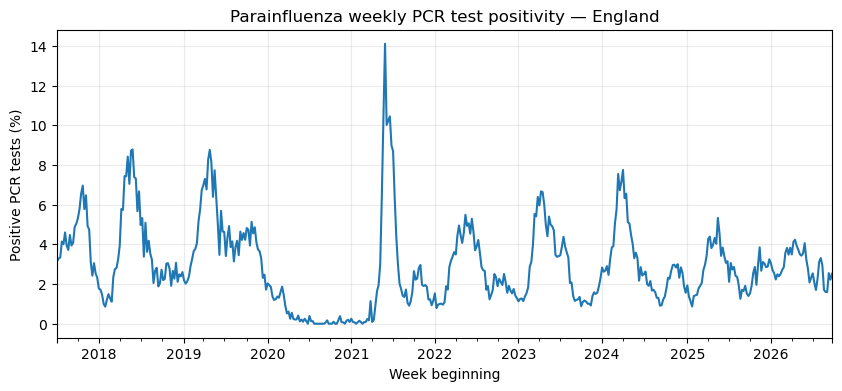

In [56]:
ax = timeseriesdf["All ages"].plot(figsize=(10, 4), color="tab:blue")
ax.set_title("Parainfluenza weekly PCR test positivity — England")
ax.set_xlabel("Week beginning")
ax.set_ylabel("Positive PCR tests (%)")
ax.grid(alpha=0.25)
plt.show()

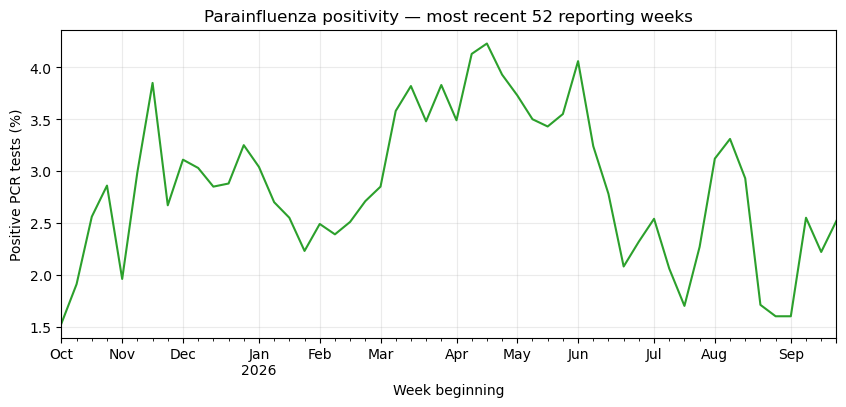

In [57]:
ax = timeseriesdf["All ages"].tail(52).plot(figsize=(10, 4), color="tab:green")
ax.set_title("Parainfluenza positivity — most recent 52 reporting weeks")
ax.set_xlabel("Week beginning")
ax.set_ylabel("Positive PCR tests (%)")
ax.grid(alpha=0.25)
plt.show()

In [58]:
from IPython.display import clear_output
import ipywidgets as wdg
import pandas as pd
import matplotlib.pyplot as plt

In [59]:
%matplotlib inline
# make figures larger
plt.rcParams['figure.dpi'] = 100

In [60]:
# our API access function. This will be called by the button when it is clicked
def access_api(button):
    # Ignore the button parameter
    #
    # put code for polling the API here
    #
    # after all is done, you can switch the icon on the button to a "check" sign
    # and optionally disable the button - it won't be needed again.
    apibutton.icon="check"
    apibutton.disabled=True

# see the doc for the parameters    
apibutton=wdg.Button(
    description='Refresh data',
    disabled=False,
    button_style='', # 'success', 'info', 'warning', 'danger' or ''
    tooltip='Click to download current Public Health England data',
    icon='download' # (FontAwesome names without the `fa-` prefix)
)

# register the callback function with the button
apibutton.on_click(access_api)

# this is an iPython function that generalises print for Jupyter Notebooks; we use it to 
# display the widgets
display(apibutton)

Button(description='Refresh data', icon='download', style=ButtonStyle(), tooltip='Click to download current Pu…

In [61]:
# Persist the correctly prepared weekly, age-stratified data for the dashboard.
timeseriesdf.to_pickle("timeseriesdf.pkl")

In [62]:
# Normally compute this from the latest API data in the cells above.
# A saved pickle makes it possible to reopen the dashboard without reprocessing.
timeseriesdf = pd.read_pickle("timeseriesdf.pkl")
timeseriesdf.index = pd.to_datetime(timeseriesdf.index)
timeseriesdf = timeseriesdf.sort_index()

In [63]:
import matplotlib.dates as mdates

# Multiple age groups can be selected together (Ctrl/Cmd-click).
age_selector = wdg.SelectMultiple(
    options=list(timeseriesdf.columns),
    value=("All ages",) if "All ages" in timeseriesdf.columns else (timeseriesdf.columns[0],),
    rows=min(8, len(timeseriesdf.columns)),
    description="Age groups:",
    style={"description_width": "initial"},
    layout=wdg.Layout(width="235px"),
)

# Year and date filters are applied together (their intersection is shown).
year_selector = wdg.Dropdown(
    options=[("All years", "all")] + [
        (str(year), year) for year in sorted(timeseriesdf.index.year.unique())
    ],
    value="all",
    description="Year:",
    layout=wdg.Layout(width="200px"),
)
start_picker = wdg.DatePicker(
    description="Start date:",
    value=timeseriesdf.index.min().date(),
    layout=wdg.Layout(width="260px"),
    style={"description_width": "initial"},
)
end_picker = wdg.DatePicker(
    description="End date:",
    value=timeseriesdf.index.max().date(),
    layout=wdg.Layout(width="260px"),
    style={"description_width": "initial"},
)
chart_selector = wdg.Dropdown(
    options=["Line", "Bar", "Scatter", "Area"],
    value="Line",
    description="Chart type:",
    style={"description_width": "initial"},
    layout=wdg.Layout(width="210px"),
)


def timeseries_graph(ages, year, start, end, chart_type):
    """Plot selected weekly positivity percentages without manufacturing zeros."""
    if not ages:
        print("Select one or more age groups to display a graph.")
        return
    if start is None or end is None:
        print("Select both a start date and an end date.")
        return
    if start > end:
        print("Start date must be on or before end date.")
        return

    selected = timeseriesdf.loc[:, list(ages)]
    selected = selected.loc[(selected.index >= pd.Timestamp(start)) &
                            (selected.index <= pd.Timestamp(end))]
    if year != "all":
        selected = selected.loc[selected.index.year == year]
    selected = selected.dropna(how="all")
    if selected.empty:
        print("No observations match these date and year filters.")
        return

    fig, ax = plt.subplots(figsize=(11, 5))
    if chart_type == "Bar":
        selected.plot.bar(ax=ax, width=0.85)
        # A decade of weekly bars can be dense; label a manageable number.
        step = max(1, (len(selected) + 11) // 12)
        positions = list(range(0, len(selected), step))
        ax.set_xticks(positions)
        ax.set_xticklabels(
            [selected.index[i].strftime("%Y-%m-%d") for i in positions],
            rotation=45, ha="right",
        )
    elif chart_type == "Area":
        selected.plot.area(ax=ax, stacked=False, alpha=0.30)
    elif chart_type == "Scatter":
        for age in selected.columns:
            ax.scatter(selected.index, selected[age], s=18, label=age, alpha=0.8)
    else:
        selected.plot.line(ax=ax, linewidth=1.8)

    if chart_type != "Bar":
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    ax.set_title("Parainfluenza weekly PCR positivity — England")
    ax.set_xlabel("Week beginning")
    ax.set_ylabel("Positive PCR tests (%)")
    ax.set_ylim(bottom=0)
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend(title="Age group")
    fig.tight_layout()
    plt.show()
    print(f"{len(selected)} reporting weeks shown | {selected.index.min():%d %b %Y}"
          f" – {selected.index.max():%d %b %Y}")


graph_controls = wdg.VBox([
    wdg.HBox([age_selector, wdg.VBox([year_selector, chart_selector])]),
    wdg.HBox([start_picker, end_picker]),
])
graph = wdg.interactive_output(
    timeseries_graph,
    {"ages": age_selector, "year": year_selector,
     "start": start_picker, "end": end_picker,
     "chart_type": chart_selector},
)
display(graph_controls, graph)

Output()